In [11]:
from __future__ import annotations

import json
import os
import platform
import shutil
import subprocess
import sys
import textwrap
import time
import tomllib
import zipfile
from datetime import datetime
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
import torch
import yaml
from IPython.display import HTML, Image, Markdown, display


def section(title: str, subtitle: str | None = None) -> None:
    """Красивый заголовок секции в выводе ноутбука."""
    subtitle_html = (
        f"<div style='color:#666;margin-top:4px'>{subtitle}</div>"
        if subtitle
        else ""
    )
    display(
        HTML(
            "<div style='padding:14px 18px;margin:8px 0 14px 0;"
            "border:1px solid #ddd;border-radius:12px;background:#fafafa'>"
            f"<div style='font-size:20px;font-weight:700'>{title}</div>"
            f"{subtitle_html}</div>"
        )
    )


def success(message: str) -> None:
    display(
        HTML(
            "<div style='padding:10px 14px;margin:8px 0;"
            "border-left:4px solid #2e7d32;background:#f5fbf5'>"
            f"{message}</div>"
        )
    )


def info(message: str) -> None:
    display(
        HTML(
            "<div style='padding:10px 14px;margin:8px 0;"
            "border-left:4px solid #607d8b;background:#f7f9fa'>"
            f"{message}</div>"
        )
    )


# fl-attacks-lab — Kaggle GPU Runner

Ноутбук предназначен для проекта **`fl-attacks-lab`** — стенда атак на обновления модели.

Он:

- автоматически находит архив **`fl-attacks-lab.zip`** среди Kaggle Inputs;
- безопасно распаковывает проект в `/kaggle/working`;
- **не меняет Flower API и версии проекта** — используется то, что закреплено в `pyproject.toml`;
- создаёт отдельное окружение вне каталога проекта на базе системного Python Kaggle;
- не просит uv скачивать отдельный Python с GitHub;
- проверяет CUDA и при необходимости ставит GPU-сборку **тех же версий** `torch`/`torchvision`;
- до запуска проверяет согласованность `experiments.yaml` и `[tool.flwr.app.config]`;
- запускает тесты проекта;
- поддерживает `clean`, `sign_flip`, `gaussian_noise`, `scaling`, `random_update` и `all`;
- после завершения показывает итоговую таблицу, графики по раундам и сравнение экспериментов;
- собирает результаты и лог в ZIP.

> **Важно:** старый локальный Flower runtime проекта не переписывается. Ноутбук только подготавливает Kaggle-среду и вызывает `run.py`.


## 1. Проверка окружения и GPU


In [12]:
section("Окружение Kaggle", "Проверяем Python, PyTorch и доступность GPU")

environment_rows = [
    ("Python", sys.version.split()[0]),
    ("Platform", platform.platform()),
    ("Notebook cwd", str(Path.cwd())),
    ("PyTorch (Kaggle kernel)", torch.__version__),
    ("CUDA build", str(torch.version.cuda)),
    ("CUDA available", str(torch.cuda.is_available())),
]

display(
    pd.DataFrame(environment_rows, columns=["Параметр", "Значение"])
    .style.hide(axis="index")
)

if not torch.cuda.is_available():
    raise RuntimeError(
        "Kaggle GPU не обнаружена. Включите GPU Accelerator и перезапустите сессию."
    )

gpu_name = torch.cuda.get_device_name(0)
success(f"GPU доступна: <b>{gpu_name}</b>")

subprocess.run(["nvidia-smi"], check=False)


Параметр,Значение
Python,3.12.13
Platform,Linux-6.12.90+-x86_64-with-glibc2.35
Notebook cwd,/kaggle/working/fl-attacks-lab
PyTorch (Kaggle kernel),2.10.0+cu128
CUDA build,12.8
CUDA available,True


Fri Sep 25 16:48:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

CompletedProcess(args=['nvidia-smi'], returncode=0)

## 2. Подключение архива проекта

Перед запуском добавьте архив **`fl-attacks-lab.zip`** в **Kaggle Input**.

Обычно ничего указывать вручную не нужно: ноутбук в первую очередь ищет **`fl-attacks-lab.zip`** (или архив, имя которого начинается с `fl-attacks-lab`). Если подходящих архивов несколько, укажите путь в `PROJECT_ARCHIVE`.


In [13]:
INPUT_ROOT = Path("/kaggle/input")
WORKING_ROOT = Path("/kaggle/working")

PROJECT_ROOT = WORKING_ROOT / "fl-attacks-lab"
STAGING_ROOT = WORKING_ROOT / "_fl_attacks_lab_staging"
PERSIST_ROOT = WORKING_ROOT / "fl-attacks-lab-persistent"
ENV_ROOT = WORKING_ROOT / "fl-attacks-lab-env"

# Обычно оставьте None.
# Пример:
# PROJECT_ARCHIVE = "/kaggle/input/fl-attacks-lab/fl-attacks-lab.zip"
PROJECT_ARCHIVE: str | None = None


def is_project_root(path: Path) -> bool:
    return (
        path.is_dir()
        and (path / "run.py").is_file()
        and (path / "pyproject.toml").is_file()
        and (path / "configs" / "experiments.yaml").is_file()
        and (path / "src" / "fl_attacks").is_dir()
    )


def find_project_roots(root: Path) -> list[Path]:
    if not root.exists():
        return []

    roots: set[Path] = set()

    for pyproject in root.rglob("pyproject.toml"):
        candidate = pyproject.parent
        if is_project_root(candidate):
            roots.add(candidate.resolve())

    return sorted(roots, key=lambda item: (len(item.parts), str(item)))


def zip_looks_like_project(path: Path) -> bool:
    try:
        with zipfile.ZipFile(path) as archive:
            names = {name.rstrip("/") for name in archive.namelist()}
    except (zipfile.BadZipFile, OSError):
        return False

    prefixes: set[str] = set()
    for name in names:
        if name.endswith("pyproject.toml"):
            prefixes.add(name[: -len("pyproject.toml")].rstrip("/"))

    for prefix in prefixes:
        base = f"{prefix}/" if prefix else ""
        if (
            f"{base}run.py" in names
            and f"{base}configs/experiments.yaml" in names
        ):
            return True

    return False


def safe_extract_zip(archive_path: Path, destination: Path) -> None:
    destination = destination.resolve()

    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            member_path = (destination / member.filename).resolve()

            if (
                member_path != destination
                and destination not in member_path.parents
            ):
                raise RuntimeError(
                    f"Небезопасный путь внутри ZIP: {member.filename}"
                )

        archive.extractall(destination)


def choose_source() -> Path:
    if PROJECT_ARCHIVE:
        source = Path(PROJECT_ARCHIVE).expanduser()
        if not source.exists():
            raise FileNotFoundError(f"PROJECT_ARCHIVE не найден: {source}")
        return source

    direct_projects = find_project_roots(INPUT_ROOT)
    named_projects = [
        path for path in direct_projects if path.name.lower() == "fl-attacks-lab"
    ]
    if len(named_projects) == 1:
        return named_projects[0]

    zip_candidates = sorted(
        path
        for path in INPUT_ROOT.rglob("*.zip")
        if zip_looks_like_project(path)
    )

    exact_archives = [
        path for path in zip_candidates if path.name.lower() == "fl-attacks-lab.zip"
    ]
    if len(exact_archives) == 1:
        return exact_archives[0]

    named_archives = [
        path
        for path in zip_candidates
        if path.stem.lower().startswith("fl-attacks-lab")
    ]
    if len(named_archives) == 1:
        return named_archives[0]

    if len(direct_projects) == 1 and not zip_candidates:
        return direct_projects[0]

    if len(zip_candidates) == 1 and not direct_projects:
        return zip_candidates[0]

    if direct_projects or zip_candidates:
        rows = [
            *[("project", str(path)) for path in direct_projects],
            *[("zip", str(path)) for path in zip_candidates],
        ]
        display(pd.DataFrame(rows, columns=["Тип", "Путь"]))
        raise RuntimeError(
            "Найдено несколько подходящих источников. "
            "Ожидается fl-attacks-lab.zip; при необходимости задайте PROJECT_ARCHIVE."
        )

    raise FileNotFoundError(
        "Проект fl-attacks-lab не найден в /kaggle/input. "
        "Добавьте fl-attacks-lab.zip через Add Input."
    )


source_path = choose_source()
section("Найден проект", str(source_path))

shutil.rmtree(STAGING_ROOT, ignore_errors=True)
STAGING_ROOT.mkdir(parents=True, exist_ok=True)

if source_path.is_file():
    if not zipfile.is_zipfile(source_path):
        raise ValueError(f"Источник не является ZIP: {source_path}")

    safe_extract_zip(source_path, STAGING_ROOT)
    roots = find_project_roots(STAGING_ROOT)
else:
    roots = (
        [source_path]
        if is_project_root(source_path)
        else find_project_roots(source_path)
    )

if len(roots) != 1:
    display(pd.DataFrame({"Кандидаты": [str(path) for path in roots]}))
    raise RuntimeError(
        f"После распаковки ожидался один корень проекта, найдено: {len(roots)}"
    )

SOURCE_PROJECT_ROOT = roots[0]
PERSIST_ROOT.mkdir(parents=True, exist_ok=True)

# Сохраняем датасеты и старые outputs при повторном выполнении этой ячейки.
for directory_name in ("data", "outputs"):
    current = PROJECT_ROOT / directory_name
    saved = PERSIST_ROOT / directory_name

    if current.exists():
        shutil.rmtree(saved, ignore_errors=True)
        shutil.move(str(current), str(saved))

shutil.rmtree(PROJECT_ROOT, ignore_errors=True)

ignored = shutil.ignore_patterns(
    ".venv",
    ".git",
    ".idea",
    ".flwr",
    ".flower-local",
    "__pycache__",
    "*.pyc",
    "*.pyo",
    ".DS_Store",
    "data",
    "outputs",
)

shutil.copytree(SOURCE_PROJECT_ROOT, PROJECT_ROOT, ignore=ignored)

for directory_name in ("data", "outputs"):
    saved = PERSIST_ROOT / directory_name
    target = PROJECT_ROOT / directory_name

    if saved.exists():
        shutil.move(str(saved), str(target))
    else:
        target.mkdir(parents=True, exist_ok=True)

os.chdir(PROJECT_ROOT)
os.environ["UV_PROJECT_ENVIRONMENT"] = str(ENV_ROOT)

success(f"Рабочая копия подготовлена: <code>{PROJECT_ROOT}</code>")


## 3. Проверка структуры новой версии стенда


In [14]:
required_paths = [
    PROJECT_ROOT / "run.py",
    PROJECT_ROOT / "pyproject.toml",
    PROJECT_ROOT / "configs" / "experiments.yaml",
    PROJECT_ROOT / "src" / "fl_attacks" / "client_app.py",
    PROJECT_ROOT / "src" / "fl_attacks" / "server_app.py",
    PROJECT_ROOT / "src" / "fl_attacks" / "attacks" / "base.py",
    PROJECT_ROOT / "src" / "fl_attacks" / "attacks" / "factory.py",
    PROJECT_ROOT / "src" / "fl_attacks" / "attacks" / "sign_flip.py",
    PROJECT_ROOT / "src" / "fl_attacks" / "attacks" / "gaussian_noise.py",
    PROJECT_ROOT / "src" / "fl_attacks" / "attacks" / "scaling.py",
    PROJECT_ROOT / "src" / "fl_attacks" / "attacks" / "random_update.py",
]

missing = [
    str(path.relative_to(PROJECT_ROOT))
    for path in required_paths
    if not path.exists()
]

if missing:
    raise FileNotFoundError(
        "Архив не соответствует новой версии model-poisoning стенда. "
        "Отсутствуют: " + ", ".join(missing)
    )

tree_rows = []
for path in sorted(PROJECT_ROOT.rglob("*")):
    relative = path.relative_to(PROJECT_ROOT)

    if any(part in {"data", "outputs", "__pycache__"} for part in relative.parts):
        continue

    if path.is_file() and len(relative.parts) <= 4:
        tree_rows.append(str(relative))

display(
    pd.DataFrame({"Файлы проекта": tree_rows})
    .head(80)
    .style.hide(axis="index")
)
success("Структура новой версии стенда подтверждена.")


Файлы проекта
configs/experiments.yaml
pyproject.toml
run.py
src/fl_attacks/__init__.py
src/fl_attacks/attacks/__init__.py
src/fl_attacks/attacks/base.py
src/fl_attacks/attacks/factory.py
src/fl_attacks/attacks/gaussian_noise.py
src/fl_attacks/attacks/random_update.py
src/fl_attacks/attacks/scaling.py


## 4. Установка окружения проекта

В Kaggle обычно уже есть системный Python 3.12. Мы **не используем `uv sync`**, потому что `uv sync` может попытаться скачать отдельный CPython с GitHub.

Вместо этого `uv` используется только как быстрый установщик пакетов: виртуальное окружение создаётся из `sys.executable` Kaggle, а версии библиотек берутся из `pyproject.toml`. Это сохраняет закреплённые версии `flwr`, `torch`, `torchvision`, `numpy`, `PyYAML` и `matplotlib`.


In [15]:
section("Подготовка окружения", "Используем системный Python Kaggle и не даём uv скачивать отдельный CPython")

project_meta = tomllib.loads(
    (PROJECT_ROOT / "pyproject.toml").read_text(encoding="utf-8")
)
dependencies = project_meta["project"]["dependencies"]

# Kaggle обычно запускает notebook на Python 3.12.
# Проект изначально был ограничен <3.12, поэтому в рабочей копии
# разрешаем 3.12. Версии библиотек при этом НЕ меняются.
python_major_minor = sys.version_info[:2]
if python_major_minor not in {(3, 11), (3, 12)}:
    raise RuntimeError(
        "Для этого стенда нужен Python 3.11 или 3.12. "
        f"В Kaggle обнаружен Python {sys.version_info.major}.{sys.version_info.minor}."
    )

pyproject_runtime = PROJECT_ROOT / "pyproject.toml"
pyproject_text = pyproject_runtime.read_text(encoding="utf-8")

if python_major_minor == (3, 12) and 'requires-python = ">=3.11,<3.12"' in pyproject_text:
    pyproject_text = pyproject_text.replace(
        'requires-python = ">=3.11,<3.12"',
        'requires-python = ">=3.11,<3.13"',
        1,
    )
    pyproject_runtime.write_text(pyproject_text, encoding="utf-8")
    project_meta = tomllib.loads(pyproject_text)
    dependencies = project_meta["project"]["dependencies"]

runtime_rows = [("Python", f"{sys.version_info.major}.{sys.version_info.minor}.{sys.version_info.micro}")]
for dependency in dependencies:
    runtime_rows.append(("Dependency", dependency))

display(
    pd.DataFrame(runtime_rows, columns=["Тип", "Значение"])
    .style.hide(axis="index")
)

uv_path = shutil.which("uv")

if uv_path is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "uv==0.11.13"],
        check=True,
    )
    uv_path = shutil.which("uv")

if uv_path is None:
    raise RuntimeError("Не удалось установить/найти uv.")

UV = uv_path
uv_version = subprocess.run(
    [UV, "--version"],
    check=True,
    text=True,
    capture_output=True,
).stdout.strip()
print(uv_version)

# Ячейку можно безопасно запускать повторно после неудачной установки.
# uv venv не перезаписывает существующий каталог без --clear.
RECREATE_ENVIRONMENT = True
if RECREATE_ENVIRONMENT:
    shutil.rmtree(ENV_ROOT, ignore_errors=True)

shutil.rmtree(PROJECT_ROOT / ".venv", ignore_errors=True)
shutil.rmtree(PROJECT_ROOT / ".flower-local", ignore_errors=True)
shutil.rmtree(PROJECT_ROOT / ".flwr", ignore_errors=True)

install_env = os.environ.copy()
install_env["UV_LINK_MODE"] = "copy"
install_env["UV_CACHE_DIR"] = str(WORKING_ROOT / ".cache" / "uv")

# Критично: передаём uv уже существующий интерпретатор Kaggle.
# Поэтому uv не ищет и не скачивает отдельный CPython с GitHub.
# --clear делает повторный запуск ячейки идемпотентным.
subprocess.run(
    [
        UV,
        "venv",
        str(ENV_ROOT),
        "--clear",
        "--python",
        sys.executable,
    ],
    cwd=PROJECT_ROOT,
    env=install_env,
    check=True,
)

venv_python = ENV_ROOT / "bin" / "python"
venv_flwr = ENV_ROOT / "bin" / "flwr"

if not venv_python.exists():
    raise RuntimeError("Не удалось создать виртуальное окружение на Python Kaggle.")

# Ставим строго те версии, которые перечислены в pyproject.toml.
# Не используем `uv sync`, чтобы не запускать управление Python-версиями.
subprocess.run(
    [
        UV,
        "pip",
        "install",
        "--python",
        str(venv_python),
        *dependencies,
        "wrapt",
    ],
    cwd=PROJECT_ROOT,
    env=install_env,
    check=True,
)

# Устанавливаем сам проект без повторной установки зависимостей.
subprocess.run(
    [
        UV,
        "pip",
        "install",
        "--python",
        str(venv_python),
        "--no-deps",
        "-e",
        ".",
    ],
    cwd=PROJECT_ROOT,
    env=install_env,
    check=True,
)


def package_pin(package_name: str) -> str | None:
    prefix = f"{package_name}=="
    for dependency in dependencies:
        if dependency.lower().startswith(prefix.lower()):
            return dependency.split("==", 1)[1]
    return None


def read_runtime_status() -> dict[str, Any]:
    script = r"""
import importlib.metadata
import json

result = {}

for package in ("flwr", "torch", "torchvision", "numpy", "PyYAML", "matplotlib"):
    try:
        result[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        result[package] = None

try:
    import torch
    result["cuda_available"] = torch.cuda.is_available()
    result["cuda_build"] = torch.version.cuda
    result["gpu"] = (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )
except Exception as error:
    result["cuda_available"] = False
    result["torch_error"] = repr(error)

print(json.dumps(result))
"""
    completed = subprocess.run(
        [str(venv_python), "-c", script],
        cwd=PROJECT_ROOT,
        env=install_env,
        check=True,
        text=True,
        capture_output=True,
    )
    return json.loads(completed.stdout)


runtime_status = read_runtime_status()

if not runtime_status.get("cuda_available"):
    torch_pin = package_pin("torch")
    torchvision_pin = package_pin("torchvision")

    if not torch_pin or not torchvision_pin:
        raise RuntimeError(
            "В pyproject.toml должны быть точно закреплены torch и torchvision."
        )

    torch_command = [
        UV,
        "pip",
        "install",
        "--python",
        str(venv_python),
        "--reinstall",
        f"torch=={torch_pin}",
        f"torchvision=={torchvision_pin}",
        "--torch-backend",
        "auto",
    ]

    print("PyTorch не видит CUDA. Переустанавливается GPU wheel тех же версий:")
    print(" ".join(torch_command))

    subprocess.run(
        torch_command,
        cwd=PROJECT_ROOT,
        env=install_env,
        check=True,
    )

    runtime_status = read_runtime_status()

expected_versions = {
    "flwr": package_pin("flwr"),
    "torch": package_pin("torch"),
    "torchvision": package_pin("torchvision"),
    "numpy": package_pin("numpy"),
    "PyYAML": package_pin("PyYAML"),
    "matplotlib": package_pin("matplotlib"),
}

for package_name, expected in expected_versions.items():
    if expected is None:
        continue
    installed = runtime_status.get(package_name)
    if installed != expected:
        raise RuntimeError(
            f"Версия {package_name} не совпадает: "
            f"ожидалась {expected}, установлена {installed}"
        )

if not runtime_status.get("cuda_available"):
    raise RuntimeError("Проектное окружение по-прежнему не видит GPU.")

display(
    pd.DataFrame(
        [
            ("Python", f"{sys.version_info.major}.{sys.version_info.minor}.{sys.version_info.micro}"),
            ("Flower", runtime_status.get("flwr")),
            ("PyTorch", runtime_status.get("torch")),
            ("Torchvision", runtime_status.get("torchvision")),
            ("NumPy", runtime_status.get("numpy")),
            ("PyYAML", runtime_status.get("PyYAML")),
            ("Matplotlib", runtime_status.get("matplotlib")),
            ("CUDA build", runtime_status.get("cuda_build")),
            ("GPU", runtime_status.get("gpu")),
        ],
        columns=["Компонент", "Значение"],
    ).style.hide(axis="index")
)

success(
    "Окружение готово: используется системный Python Kaggle, "
    "а версии библиотек сохранены строго по pyproject.toml."
)


Тип,Значение
Python,3.12.13
Dependency,flwr==1.32.1
Dependency,torch==2.2.2
Dependency,torchvision==0.17.2
Dependency,numpy==1.26.4
Dependency,PyYAML==6.0.2
Dependency,matplotlib==3.8.4


uv 0.11.13 (x86_64-unknown-linux-gnu)


Using CPython 3.12.13 interpreter at: /usr/bin/python3
Creating virtual environment at: /kaggle/working/fl-attacks-lab-env
Activate with: source /kaggle/working/fl-attacks-lab-env/bin/activate
Using Python 3.12.13 environment at: /kaggle/working/fl-attacks-lab-env
Resolved 63 packages in 559ms
Prepared 1 package in 25ms
Installed 63 packages in 5.85s
 + alembic==1.20.0
 + certifi==2026.7.22
 + cffi==2.1.1
 + charset-normalizer==3.5.1
 + click==8.5.0
 + contourpy==1.3.3
 + cryptography==46.0.7
 + cycler==0.12.1
 + filelock==4.0.3
 + flwr==1.32.1
 + fonttools==4.66.0
 + fsspec==2026.9.0
 + grpcio==1.84.0
 + grpcio-health-checking==1.81.1
 + idna==3.20
 + iterators==0.0.2
 + jinja2==3.1.6
 + kiwisolver==1.5.1
 + mako==1.4.3
 + markdown-it-py==4.2.0
 + markupsafe==3.0.3
 + matplotlib==3.8.4
 + mdurl==0.1.2
 + mpmath==1.3.0
 + networkx==3.7
 + numpy==1.26.4
 + nvidia-cublas-cu12==12.1.3.1
 + nvidia-cuda-cupti-cu12==12.1.105
 + nvidia-cuda-nvrtc-cu12==12.1.105
 + nvidia-cuda-runtime-cu12==12

Компонент,Значение
Python,3.12.13
Flower,1.32.1
PyTorch,2.2.2
Torchvision,0.17.2
NumPy,1.26.4
PyYAML,6.0.2
Matplotlib,3.8.4
CUDA build,12.1
GPU,Tesla T4


## 5. Smoke-check модели и Flower runtime

Здесь дополнительно проверяется, что приложение запускается внутри созданного окружения, а не в системном Python notebook.


In [16]:
verification_script = textwrap.dedent(
    """
    import shutil

    import flwr
    import torch
    import torchvision

    from fl_attacks.models import create_model

    if not torch.cuda.is_available():
        raise RuntimeError("CUDA unavailable")

    device = torch.device("cuda:0")

    model = create_model(
        in_channels=3,
        num_classes=100,
    ).to(device)

    sample = torch.randn(2, 3, 32, 32, device=device)

    with torch.no_grad():
        output = model(sample)

    if tuple(output.shape) != (2, 100):
        raise RuntimeError(f"Unexpected output shape: {tuple(output.shape)}")

    required_commands = (
        "flwr",
        "flower-superlink",
        "flower-supernode",
    )

    missing = [
        command
        for command in required_commands
        if shutil.which(command) is None
    ]

    if missing:
        raise RuntimeError(f"Missing Flower commands: {missing}")

    print("Flower:", flwr.__version__)
    print("PyTorch:", torch.__version__)
    print("Torchvision:", torchvision.__version__)
    print("GPU:", torch.cuda.get_device_name(0))
    print("Model output:", tuple(output.shape))
    print(
        "Parameters:",
        sum(parameter.numel() for parameter in model.parameters()),
    )
    """
)

verification_env = os.environ.copy()
verification_env["UV_PROJECT_ENVIRONMENT"] = str(ENV_ROOT)
verification_env["PATH"] = (
    f"{ENV_ROOT / 'bin'}:" + verification_env.get("PATH", "")
)

completed = subprocess.run(
    [str(venv_python), "-c", verification_script],
    cwd=PROJECT_ROOT,
    env=verification_env,
    check=True,
    text=True,
    capture_output=True,
)

print(completed.stdout)
success("Модель, CUDA и Flower CLI прошли smoke-check.")


Flower: 1.32.1
PyTorch: 2.2.2+cu121
Torchvision: 0.17.2+cu121
GPU: Tesla T4
Model output: (2, 100)
Parameters: 689668



## 6. Конфигурация и preflight-проверка

Здесь ноутбук заранее проверяет:

- какие эксперименты доступны;
- что используются только model-poisoning атаки новой версии;
- что каждый ключ, отправляемый через `--run-config`, объявлен в `[tool.flwr.app.config]`.

Это ловит ошибки конфигурации **до** запуска SuperLink/SuperNode.


In [17]:
# Python runtime note: Kaggle Python 3.12 is allowed by the notebook runtime copy.
config_path = PROJECT_ROOT / "configs" / "experiments.yaml"
pyproject_path = PROJECT_ROOT / "pyproject.toml"

config_data = yaml.safe_load(config_path.read_text(encoding="utf-8"))
project_meta = tomllib.loads(pyproject_path.read_text(encoding="utf-8"))

defaults = config_data.get("defaults", {})
experiments = config_data.get("experiments", [])
app_config = (
    project_meta.get("tool", {})
    .get("flwr", {})
    .get("app", {})
    .get("config", {})
)

if not isinstance(defaults, dict) or not isinstance(experiments, list):
    raise ValueError("Некорректная структура configs/experiments.yaml")

RUNTIME_ONLY_KEYS = {"client-cpus", "client-gpus"}
SUPPORTED_ATTACKS = {
    "none",
    "sign_flip",
    "gaussian_noise",
    "scaling",
    "random_update",
}

resolved_experiments: list[dict[str, Any]] = []

for item in experiments:
    resolved = dict(defaults) | dict(item)
    resolved_experiments.append(resolved)

experiment_names = [str(item["name"]) for item in resolved_experiments]
attacks = {str(item["attack"]).lower() for item in resolved_experiments}

unsupported_attacks = attacks - SUPPORTED_ATTACKS
if unsupported_attacks:
    raise RuntimeError(
        "В конфигурации найдены атаки не из новой model-poisoning версии: "
        + ", ".join(sorted(unsupported_attacks))
    )

keys_sent_to_flower: set[str] = {"output-dir"}

for resolved in resolved_experiments:
    keys_sent_to_flower.update(
        key
        for key in resolved
        if key != "name" and key not in RUNTIME_ONLY_KEYS
    )

missing_app_keys = sorted(keys_sent_to_flower - set(app_config))

if missing_app_keys:
    raise RuntimeError(
        "experiments.yaml и pyproject.toml рассинхронизированы. "
        "В [tool.flwr.app.config] отсутствуют ключи: "
        + ", ".join(missing_app_keys)
    )

rows = []
for resolved in resolved_experiments:
    rows.append(
        {
            "Эксперимент": resolved["name"],
            "Атака": resolved["attack"],
            "Dataset": resolved["dataset"],
            "Strategy": resolved["strategy"],
            "Clients": resolved["num-clients"],
            "Malicious fraction": resolved["malicious-fraction"],
            "Rounds": resolved["num-server-rounds"],
        }
    )

display(
    pd.DataFrame(rows)
    .style
    .format({"Malicious fraction": "{:.2f}"})
    .hide(axis="index")
)

success(
    "Preflight OK: experiments.yaml согласован с pyproject.toml, "
    "все run-config ключи объявлены."
)


Эксперимент,Атака,Dataset,Strategy,Clients,Malicious fraction,Rounds
clean,none,cifar100,fedavg,5,0.70,10
sign_flip,sign_flip,cifar100,fedavg,5,0.70,10
gaussian_noise,gaussian_noise,cifar100,fedavg,5,0.70,10
scaling,scaling,cifar100,fedavg,5,0.70,10
random_update,random_update,cifar100,fedavg,5,0.70,10


## 8. Выбор эксперимента

Доступно:

- `clean`
- `sign_flip`
- `gaussian_noise`
- `scaling`
- `random_update`
- `all`

Для полного сравнительного прогона оставьте `EXPERIMENT = "all"`.


In [18]:
EXPERIMENT = "all"

# Чистый вывод удобнее для Kaggle. Если нужен полный Flower stream — True.
STREAM_FLOWER_LOGS = True

# Для CIFAR-100 при all confusion matrix очень большая,
# поэтому по умолчанию показываем её только при одиночном эксперименте.
SHOW_CONFUSION_MATRICES = EXPERIMENT != "all"

if EXPERIMENT != "all" and EXPERIMENT not in experiment_names:
    raise ValueError(
        f"Неизвестный эксперимент: {EXPERIMENT}. "
        f"Доступны: {', '.join(experiment_names)}"
    )

section(
    "Параметры запуска",
    f"experiment={EXPERIMENT}, stream={STREAM_FLOWER_LOGS}",
)


## 9. Запуск эксперимента


In [19]:
def stop_flower_processes() -> None:
    patterns = (
        "flower-supernode",
        "flower-superlink",
        "flwr run",
    )

    for pattern in patterns:
        subprocess.run(
            ["pkill", "-f", pattern],
            check=False,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
        )


os.chdir(PROJECT_ROOT)
stop_flower_processes()

shutil.rmtree(PROJECT_ROOT / ".venv", ignore_errors=True)

output_root = PROJECT_ROOT / "outputs"
output_root.mkdir(parents=True, exist_ok=True)

before_output_dirs = {
    path.resolve()
    for path in output_root.iterdir()
    if path.is_dir()
}

run_started_at = time.time()
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
LOG_PATH = WORKING_ROOT / f"fl-attacks-lab_{EXPERIMENT}_{timestamp}.log"

command = [
    str(venv_python),
    "run.py",
    "--experiment",
    EXPERIMENT,
]

if not STREAM_FLOWER_LOGS:
    command.append("--no-stream")

run_env = verification_env.copy()
run_env["PYTHONUNBUFFERED"] = "1"
run_env["MPLBACKEND"] = "Agg"
run_env["CUDA_VISIBLE_DEVICES"] = "0"
run_env["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
run_env["UV_LINK_MODE"] = "copy"

section("Запуск", " ".join(command))
print("Лог:", LOG_PATH)
print("=" * 88)

process: subprocess.Popen[str] | None = None

try:
    with LOG_PATH.open("w", encoding="utf-8", buffering=1) as log_file:
        process = subprocess.Popen(
            command,
            cwd=PROJECT_ROOT,
            env=run_env,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        assert process.stdout is not None

        for line in process.stdout:
            print(line, end="")
            log_file.write(line)

        return_code = process.wait()

    if return_code != 0:
        log_tail = LOG_PATH.read_text(
            encoding="utf-8",
            errors="replace",
        ).splitlines()[-100:]

        print("\n" + "=" * 88)
        print("ПОСЛЕДНИЕ СТРОКИ ЛОГА:")
        print("\n".join(log_tail))

        raise RuntimeError(
            f"Эксперимент завершился с кодом {return_code}. Лог: {LOG_PATH}"
        )

finally:
    stop_flower_processes()

after_output_dirs = {
    path.resolve()
    for path in output_root.iterdir()
    if path.is_dir()
}

CURRENT_OUTPUT_DIRS = sorted(
    after_output_dirs - before_output_dirs,
    key=lambda path: path.stat().st_mtime,
)

if not CURRENT_OUTPUT_DIRS:
    CURRENT_OUTPUT_DIRS = sorted(
        [
            path.resolve()
            for path in output_root.iterdir()
            if path.is_dir() and path.stat().st_mtime >= run_started_at - 2
        ],
        key=lambda path: path.stat().st_mtime,
    )

success(
    f"Запуск завершён. Создано каталогов результатов: "
    f"<b>{len(CURRENT_OUTPUT_DIRS)}</b>"
)


Лог: /kaggle/working/fl-attacks-lab_all_20260925_164904.log

=== clean: downloading/checking cifar100 ===
Files already downloaded and verified
Files already downloaded and verified
=== Starting local Flower federation: 5 clients ===
=== Running clean ===
Using SuperLink: local-deployment (127.0.0.1:9093)
Successfully started run 16198728112069472141
INFO :      Starting logstream for run_id `16198728112069472141`
INFO :      Start `flwr-serverapp` process
Files already downloaded and verified
INFO :      Starting FedAvg strategy:
INFO :      	├── Number of rounds: 10
INFO :      	├── ArrayRecord (2.64 MB)
INFO :      	├── ConfigRecord (train): (empty!)
INFO :      	├── ConfigRecord (evaluate): (empty!)
INFO :      	├──> Sampling:
INFO :      	│	├──Fraction: train (1.00) | evaluate ( 1.00)
INFO :      	│	├──Minimum nodes: train (2) | evaluate (2)
INFO :      	│	└──Minimum available nodes: 5
INFO :      	└──> Keys in records:
INFO :      		├── Weighted by: 'num-examples'
INFO :      		├

## 10. Итоговая таблица и визуализация


Experiment,Attack,Strategy,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted,Loss
clean,none,fedavg,0.2408,0.2708,0.2408,0.2024,0.2024,3.0632
sign_flip,sign_flip,fedavg,0.0100,0.0001,0.0100,0.0002,0.0002,5803932363.9808
gaussian_noise,gaussian_noise,fedavg,0.2317,0.2561,0.2317,0.1975,0.1975,3.0922
scaling,scaling,fedavg,0.0100,0.0001,0.0100,0.0002,0.0002,33.7089
random_update,random_update,fedavg,0.0635,0.0389,0.0635,0.0251,0.0251,4.8605


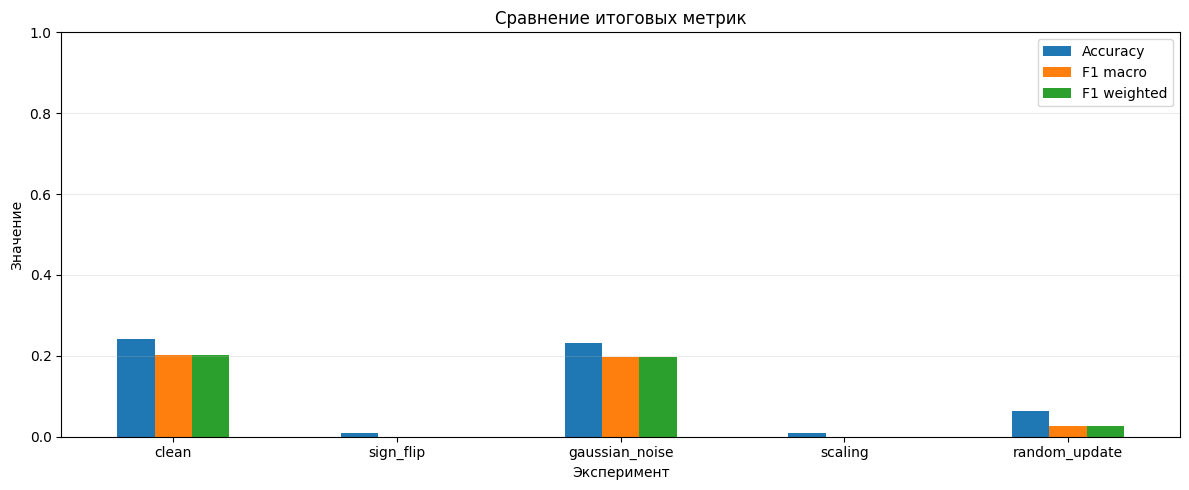

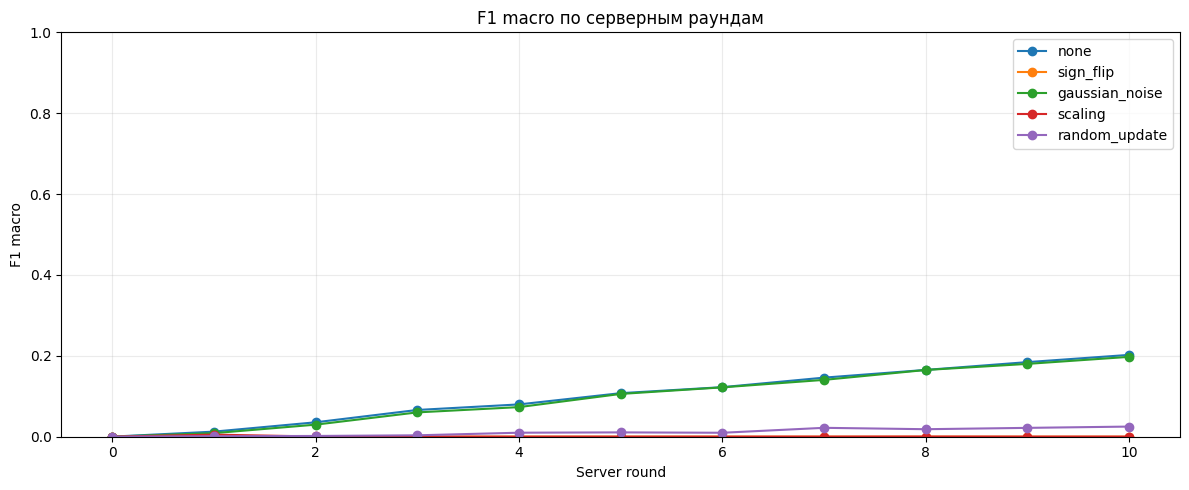

In [20]:
def load_yaml(path: Path) -> dict[str, Any]:
    value = yaml.safe_load(path.read_text(encoding="utf-8"))
    return value if isinstance(value, dict) else {}


def final_metrics_from_directory(
    directory: Path,
) -> dict[str, Any] | None:
    metrics_path = directory / "metrics.csv"

    if not metrics_path.exists():
        return None

    frame = pd.read_csv(metrics_path)

    if frame.empty:
        return None

    final_row = frame.iloc[-1]
    config = (
        load_yaml(directory / "config.yaml")
        if (directory / "config.yaml").exists()
        else {}
    )

    return {
        "Experiment": directory.name.split("__")[-1],
        "Attack": config.get("attack", ""),
        "Strategy": config.get("strategy", ""),
        "Accuracy": float(final_row.get("clean_accuracy", 0.0)),
        "Precision macro": float(
            final_row.get("clean_precision_macro", 0.0)
        ),
        "Recall macro": float(final_row.get("clean_recall_macro", 0.0)),
        "F1 macro": float(final_row.get("clean_f1_macro", 0.0)),
        "F1 weighted": float(final_row.get("clean_f1_weighted", 0.0)),
        "Loss": float(final_row.get("clean_loss", 0.0)),
        "Directory": str(directory.relative_to(PROJECT_ROOT)),
    }


summary_rows = [
    row
    for directory in CURRENT_OUTPUT_DIRS
    if (row := final_metrics_from_directory(directory)) is not None
]

if not summary_rows:
    raise RuntimeError(
        "Не удалось найти metrics.csv для текущего запуска."
    )

RESULT_SUMMARY = pd.DataFrame(summary_rows)

section(
    "Итоговые метрики",
    "Последний серверный раунд каждого эксперимента",
)

metric_columns = [
    "Accuracy",
    "Precision macro",
    "Recall macro",
    "F1 macro",
    "F1 weighted",
    "Loss",
]

display(
    RESULT_SUMMARY[
        [
            "Experiment",
            "Attack",
            "Strategy",
            *metric_columns,
        ]
    ]
    .style
    .format(
        {
            "Accuracy": "{:.4f}",
            "Precision macro": "{:.4f}",
            "Recall macro": "{:.4f}",
            "F1 macro": "{:.4f}",
            "F1 weighted": "{:.4f}",
            "Loss": "{:.4f}",
        }
    )
    .hide(axis="index")
)

comparison = (
    RESULT_SUMMARY
    .set_index("Experiment")[["Accuracy", "F1 macro", "F1 weighted"]]
)

ax = comparison.plot(
    kind="bar",
    figsize=(12, 5),
    rot=0,
)
ax.set_title("Сравнение итоговых метрик")
ax.set_xlabel("Эксперимент")
ax.set_ylabel("Значение")
ax.set_ylim(0.0, 1.0)
ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

for directory in CURRENT_OUTPUT_DIRS:
    metrics_path = directory / "metrics.csv"

    if not metrics_path.exists():
        continue

    frame = pd.read_csv(metrics_path)
    if frame.empty:
        continue

    config = (
        load_yaml(directory / "config.yaml")
        if (directory / "config.yaml").exists()
        else {}
    )
    label = str(config.get("attack", directory.name))

    plt.plot(
        frame["round"],
        frame["clean_f1_macro"],
        marker="o",
        label=label,
    )

plt.title("F1 macro по серверным раундам")
plt.xlabel("Server round")
plt.ylabel("F1 macro")
plt.ylim(0.0, 1.0)
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


## 11. Готовые графики каждого эксперимента


### `none`

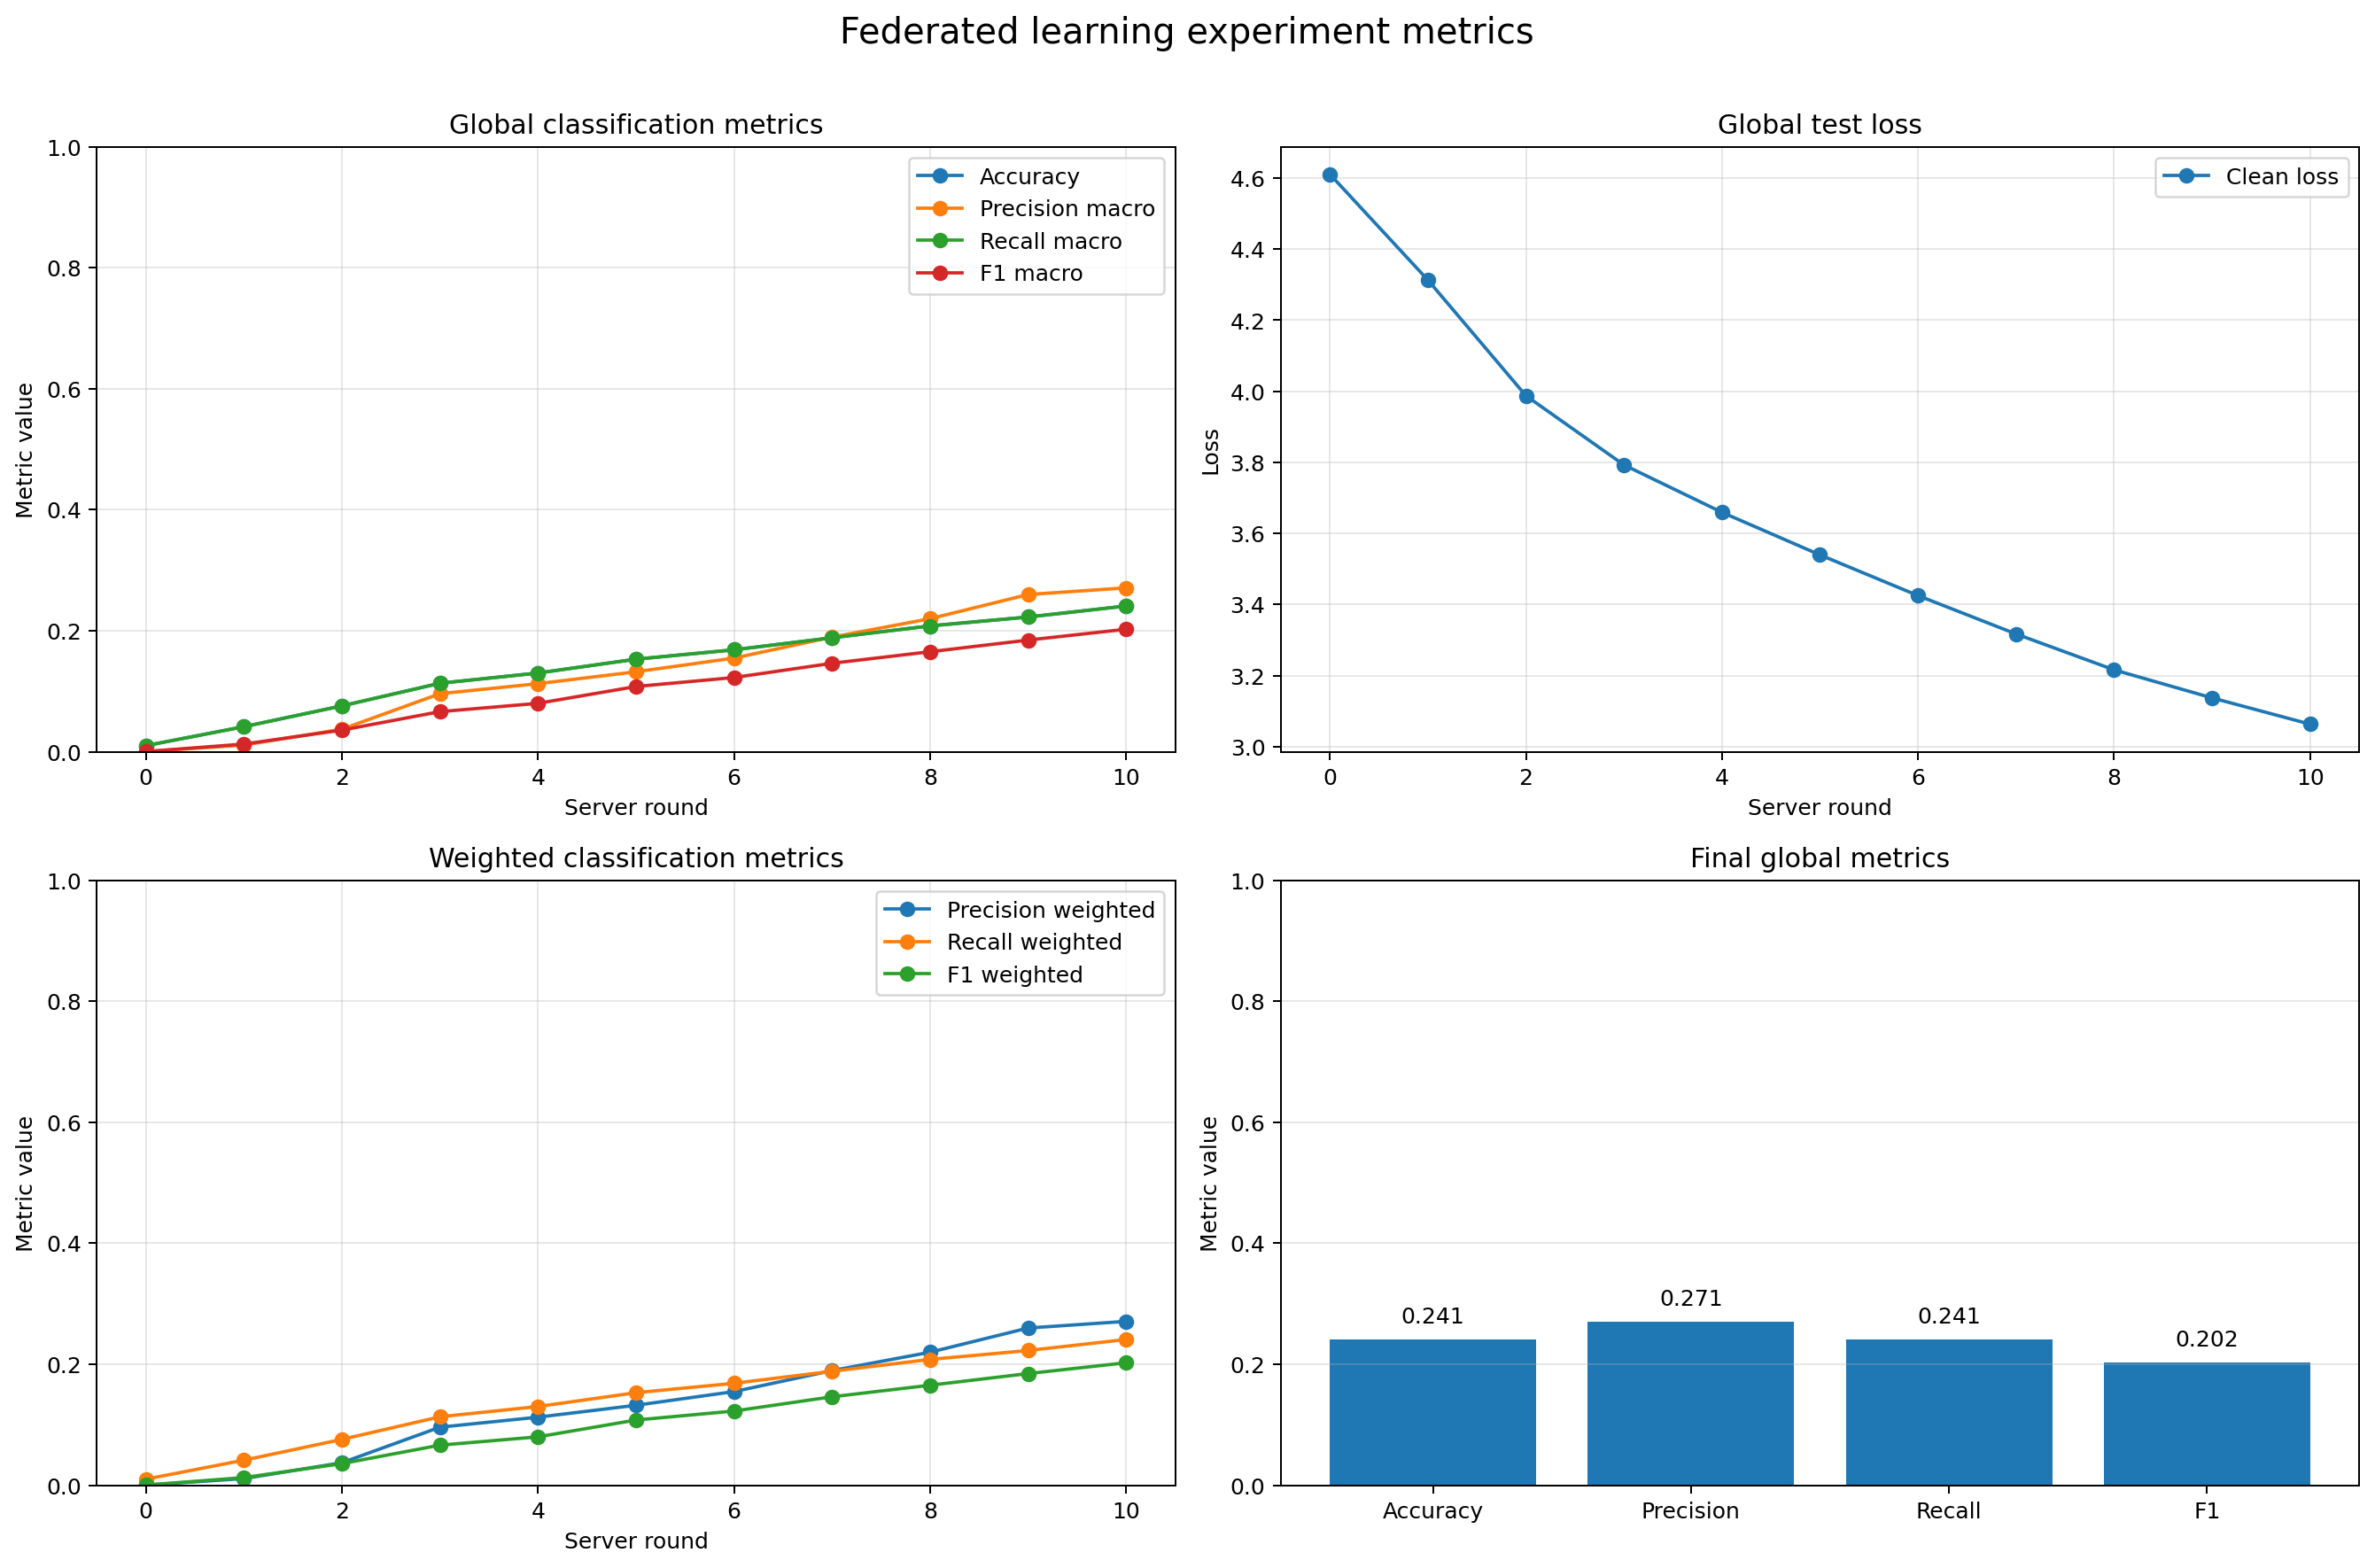

Метрика,Значение
Accuracy,0.2408
Loss,3.0632
Precision macro,0.2708
Recall macro,0.2408
F1 macro,0.2024
Precision weighted,0.2708
Recall weighted,0.2408
F1 weighted,0.2024


### `sign_flip`

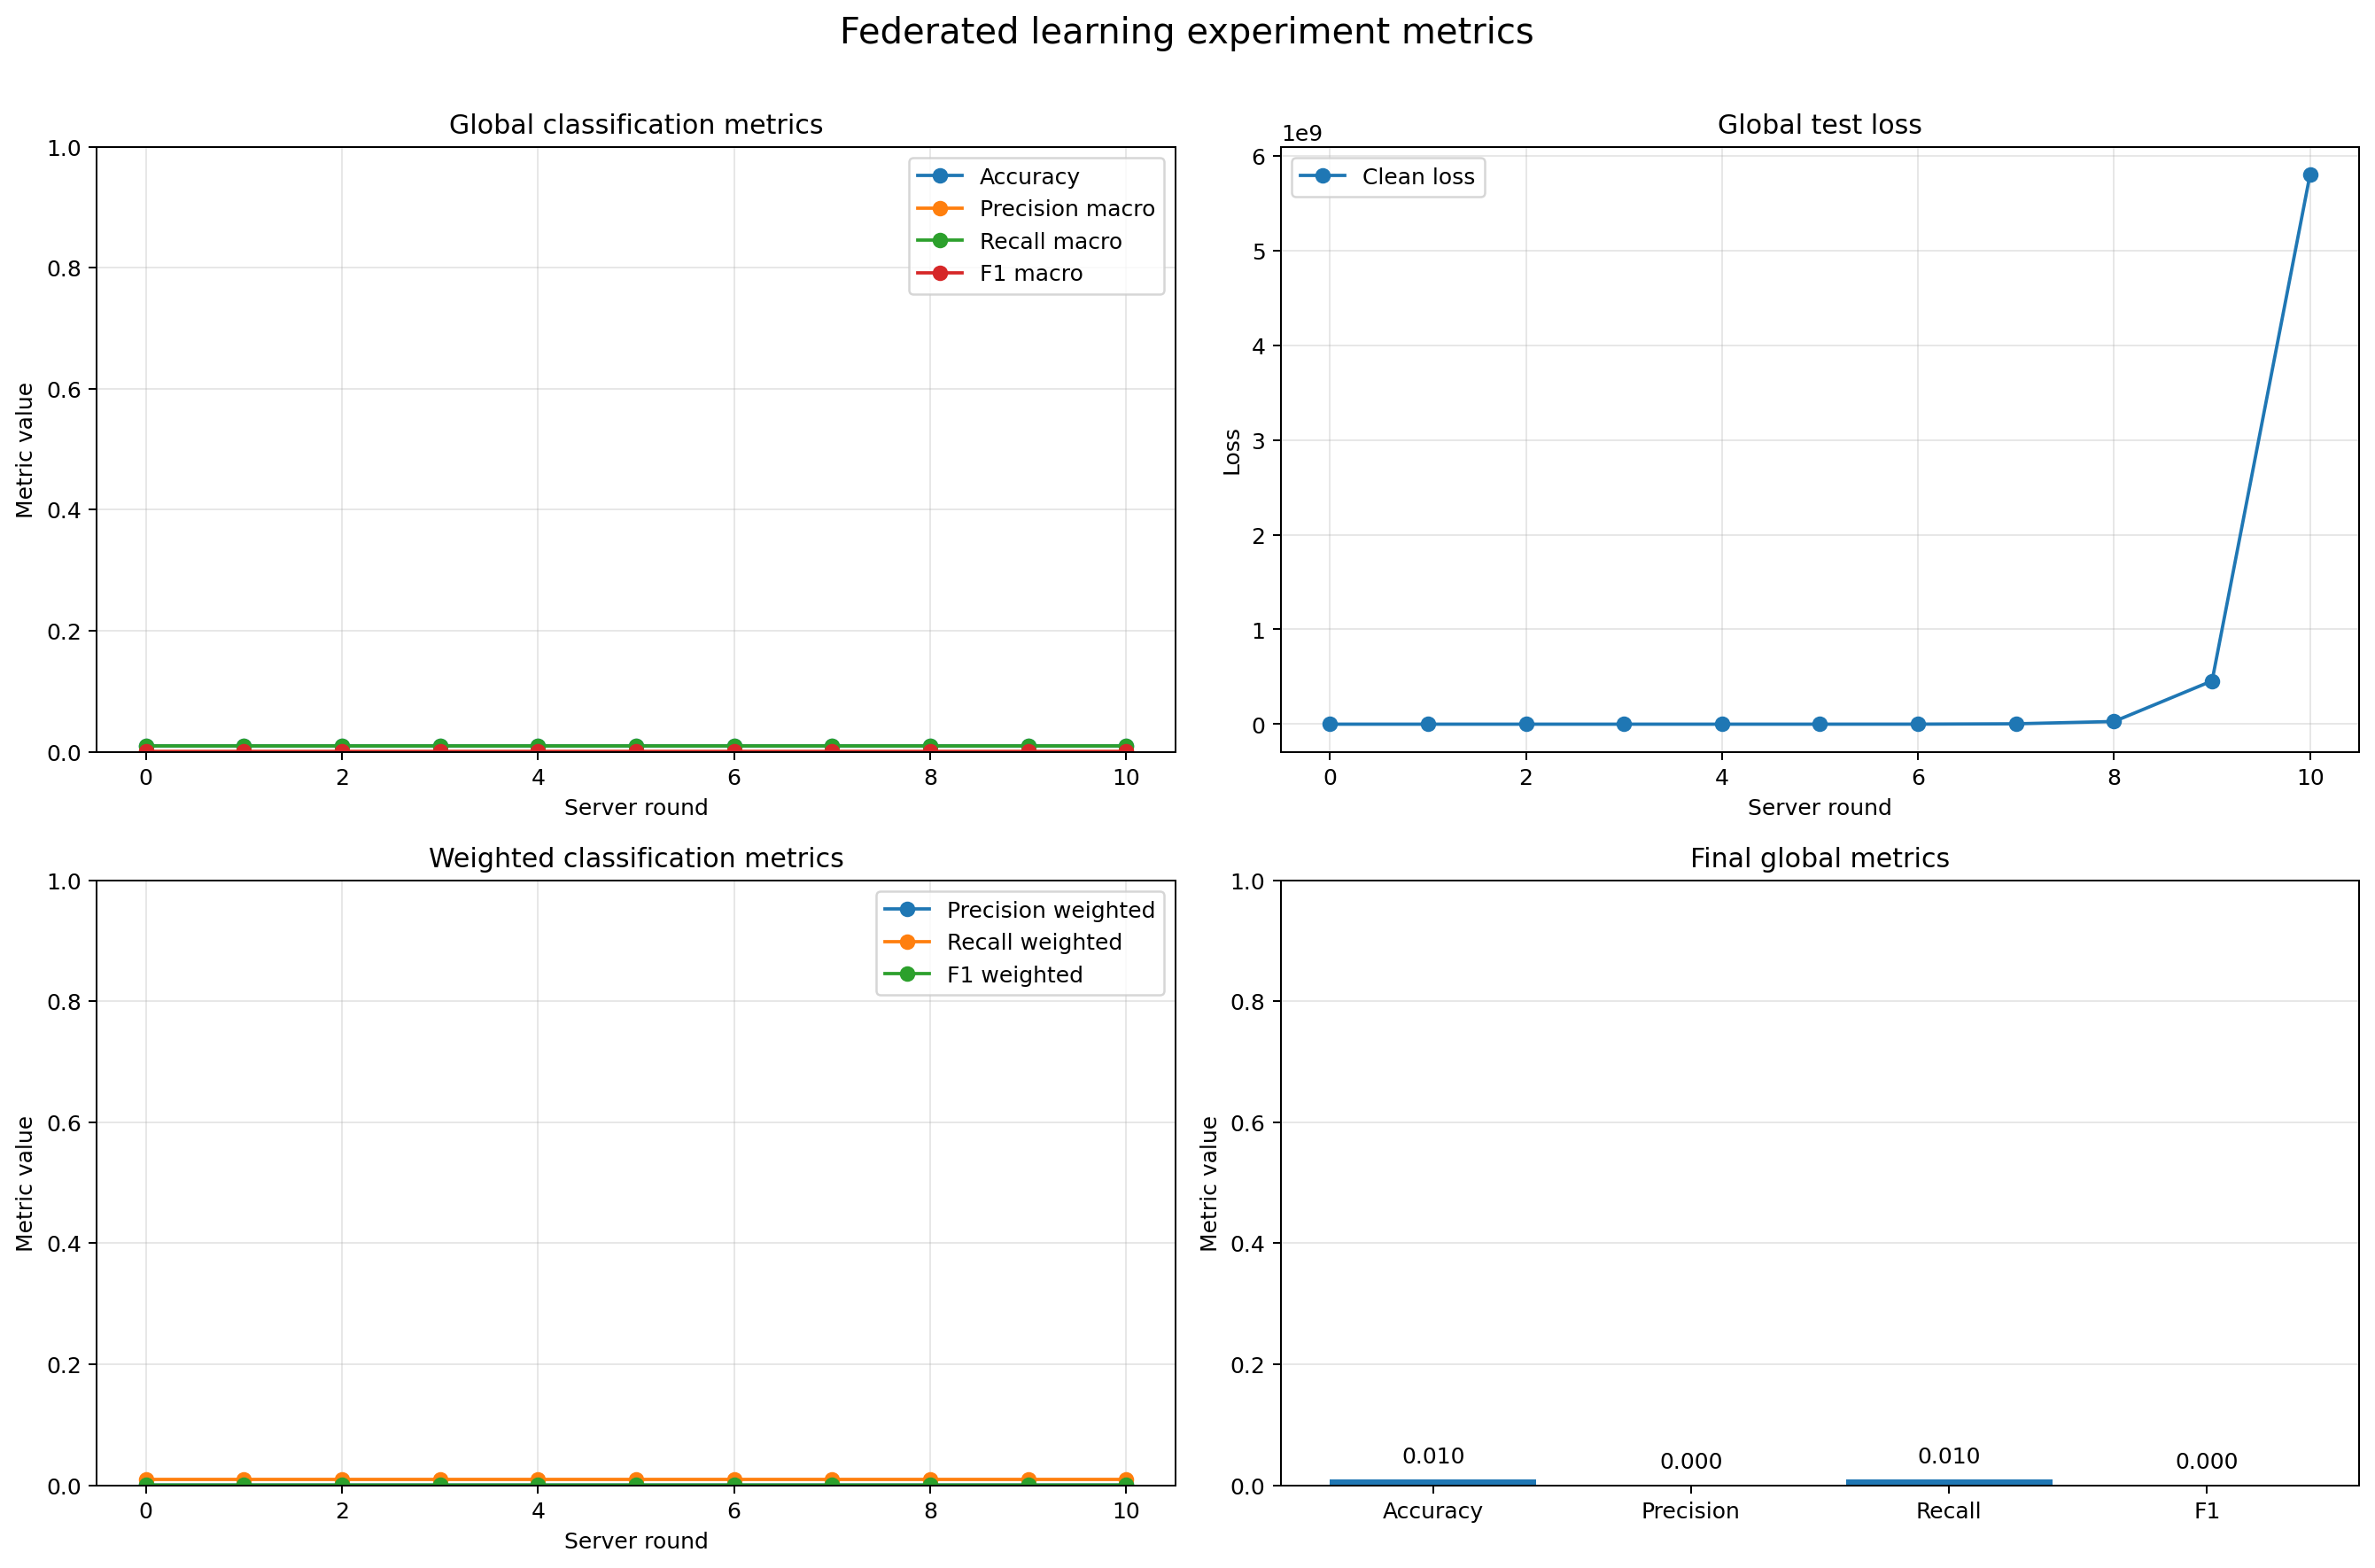

Метрика,Значение
Accuracy,0.0100
Loss,5803932363.9808
Precision macro,0.0001
Recall macro,0.0100
F1 macro,0.0002
Precision weighted,0.0001
Recall weighted,0.0100
F1 weighted,0.0002


### `gaussian_noise`

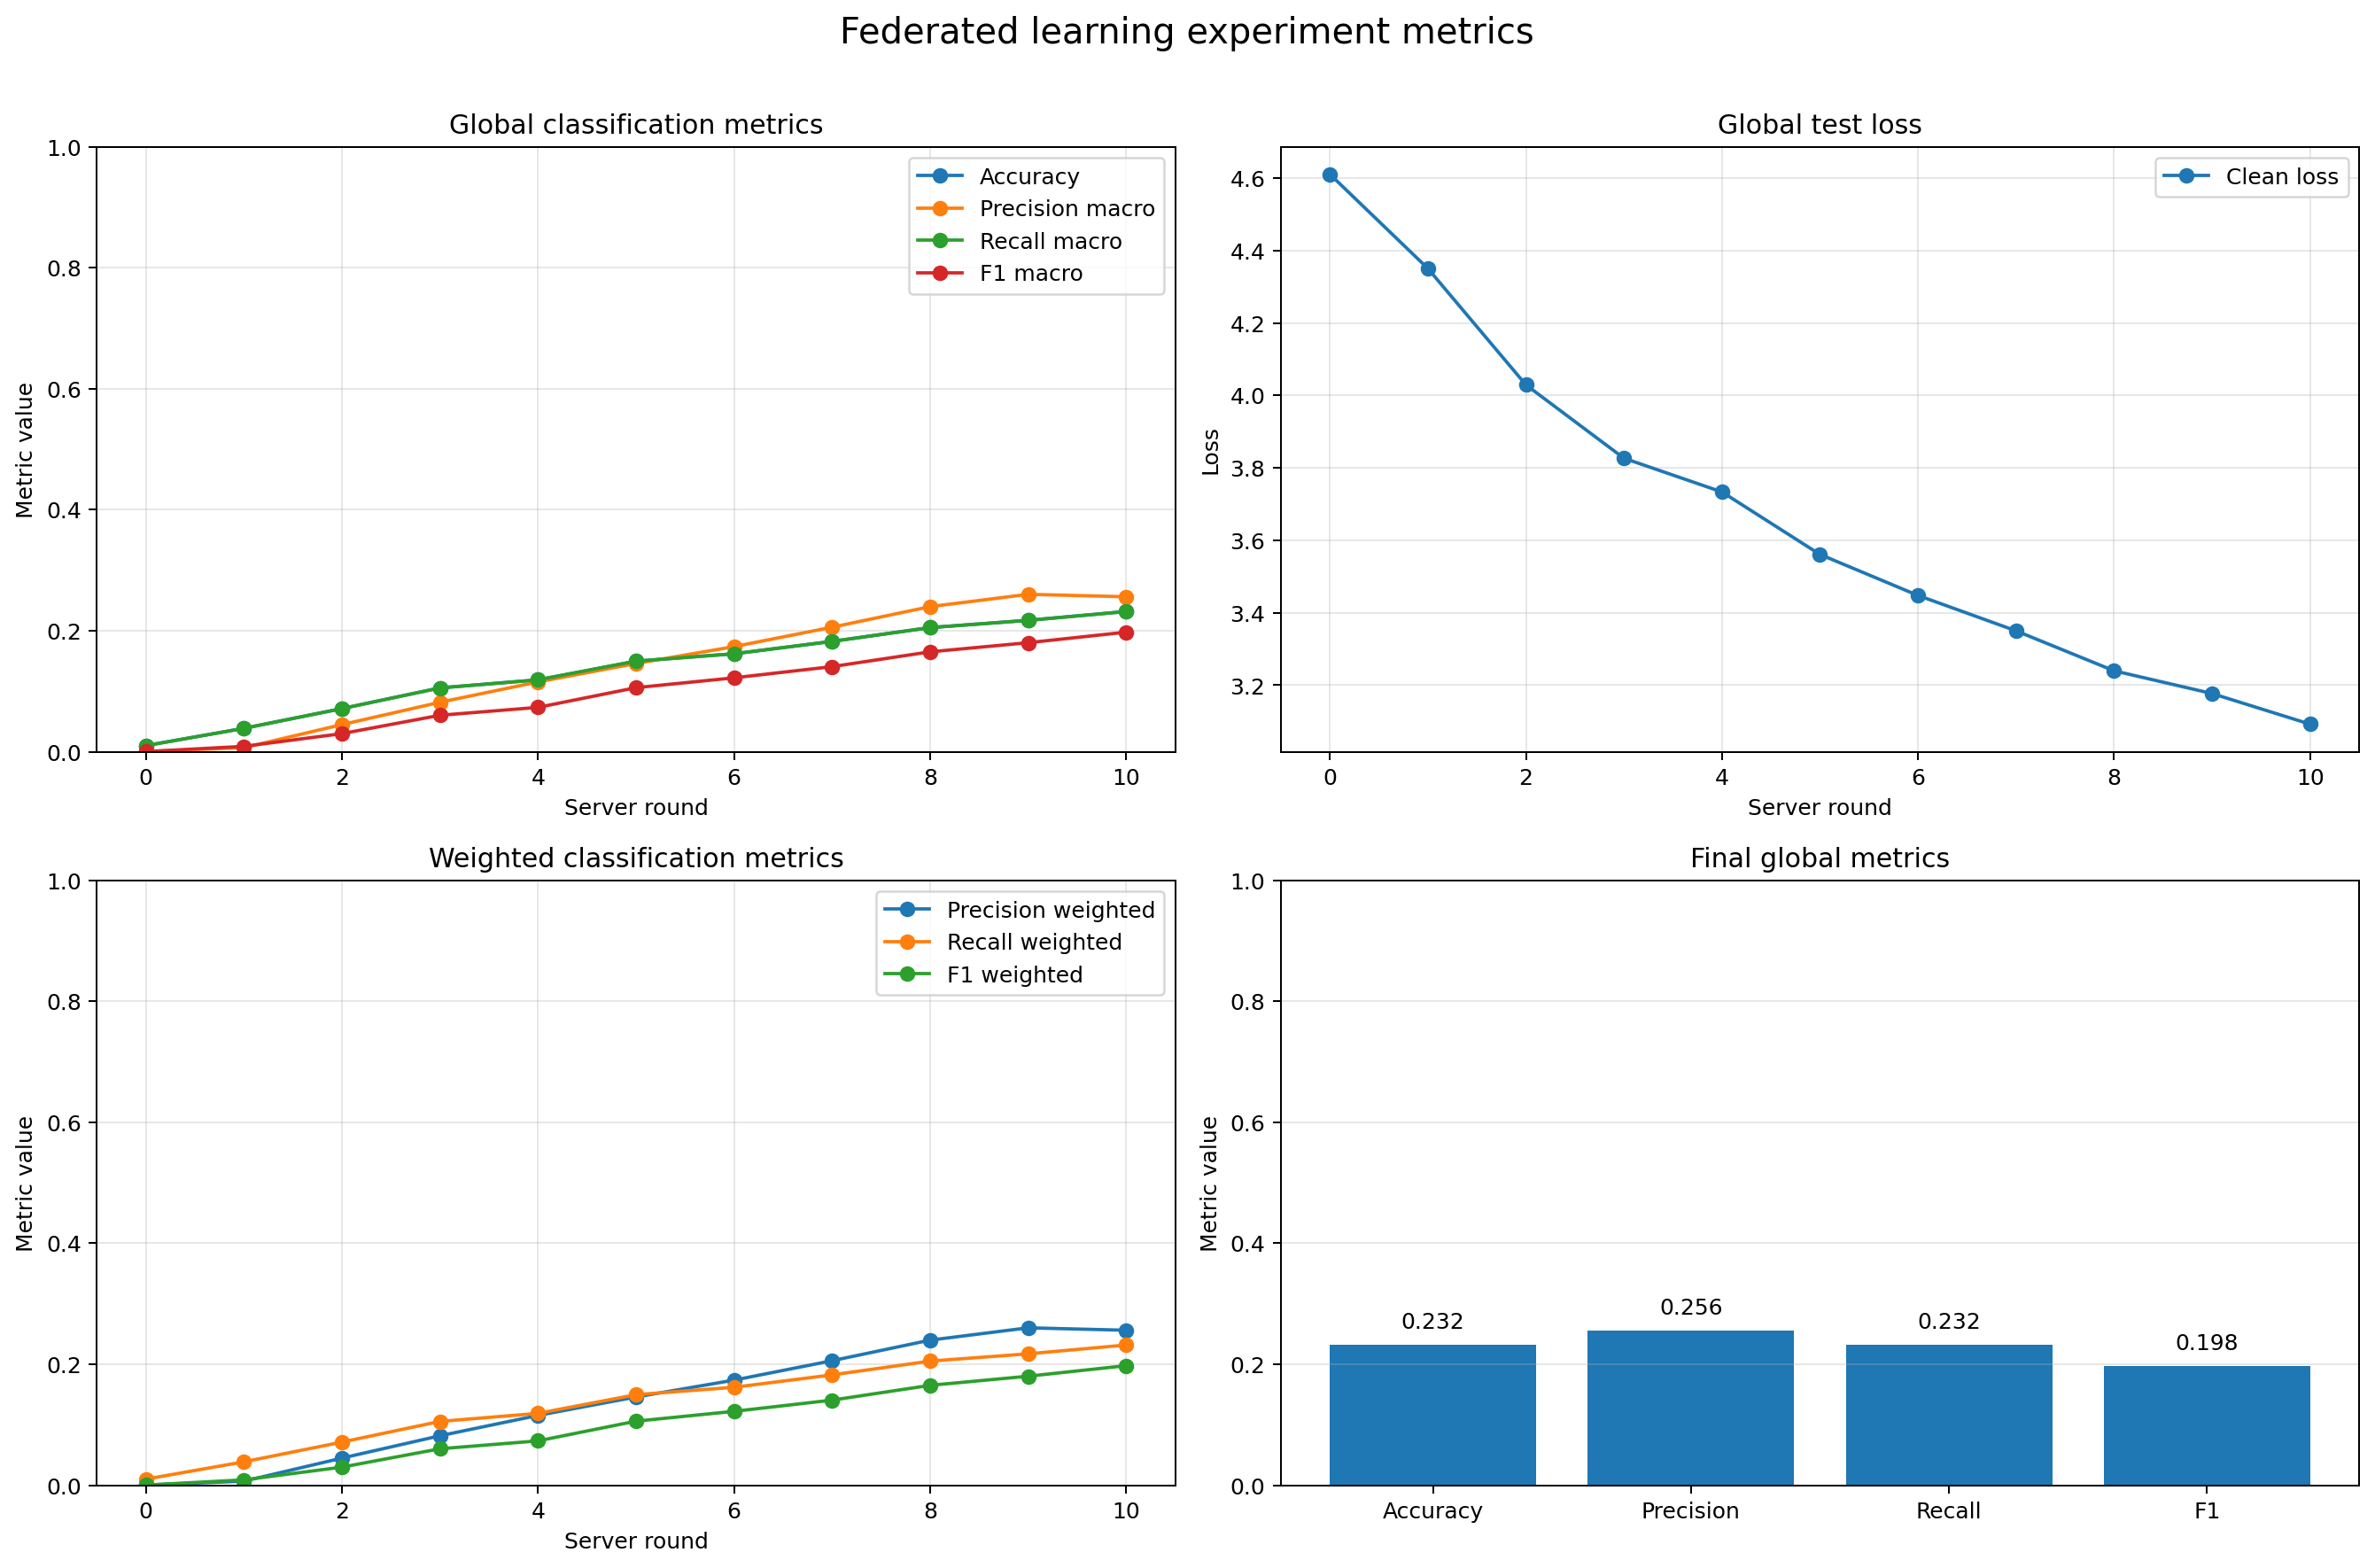

Метрика,Значение
Accuracy,0.2317
Loss,3.0922
Precision macro,0.2561
Recall macro,0.2317
F1 macro,0.1975
Precision weighted,0.2561
Recall weighted,0.2317
F1 weighted,0.1975


### `scaling`

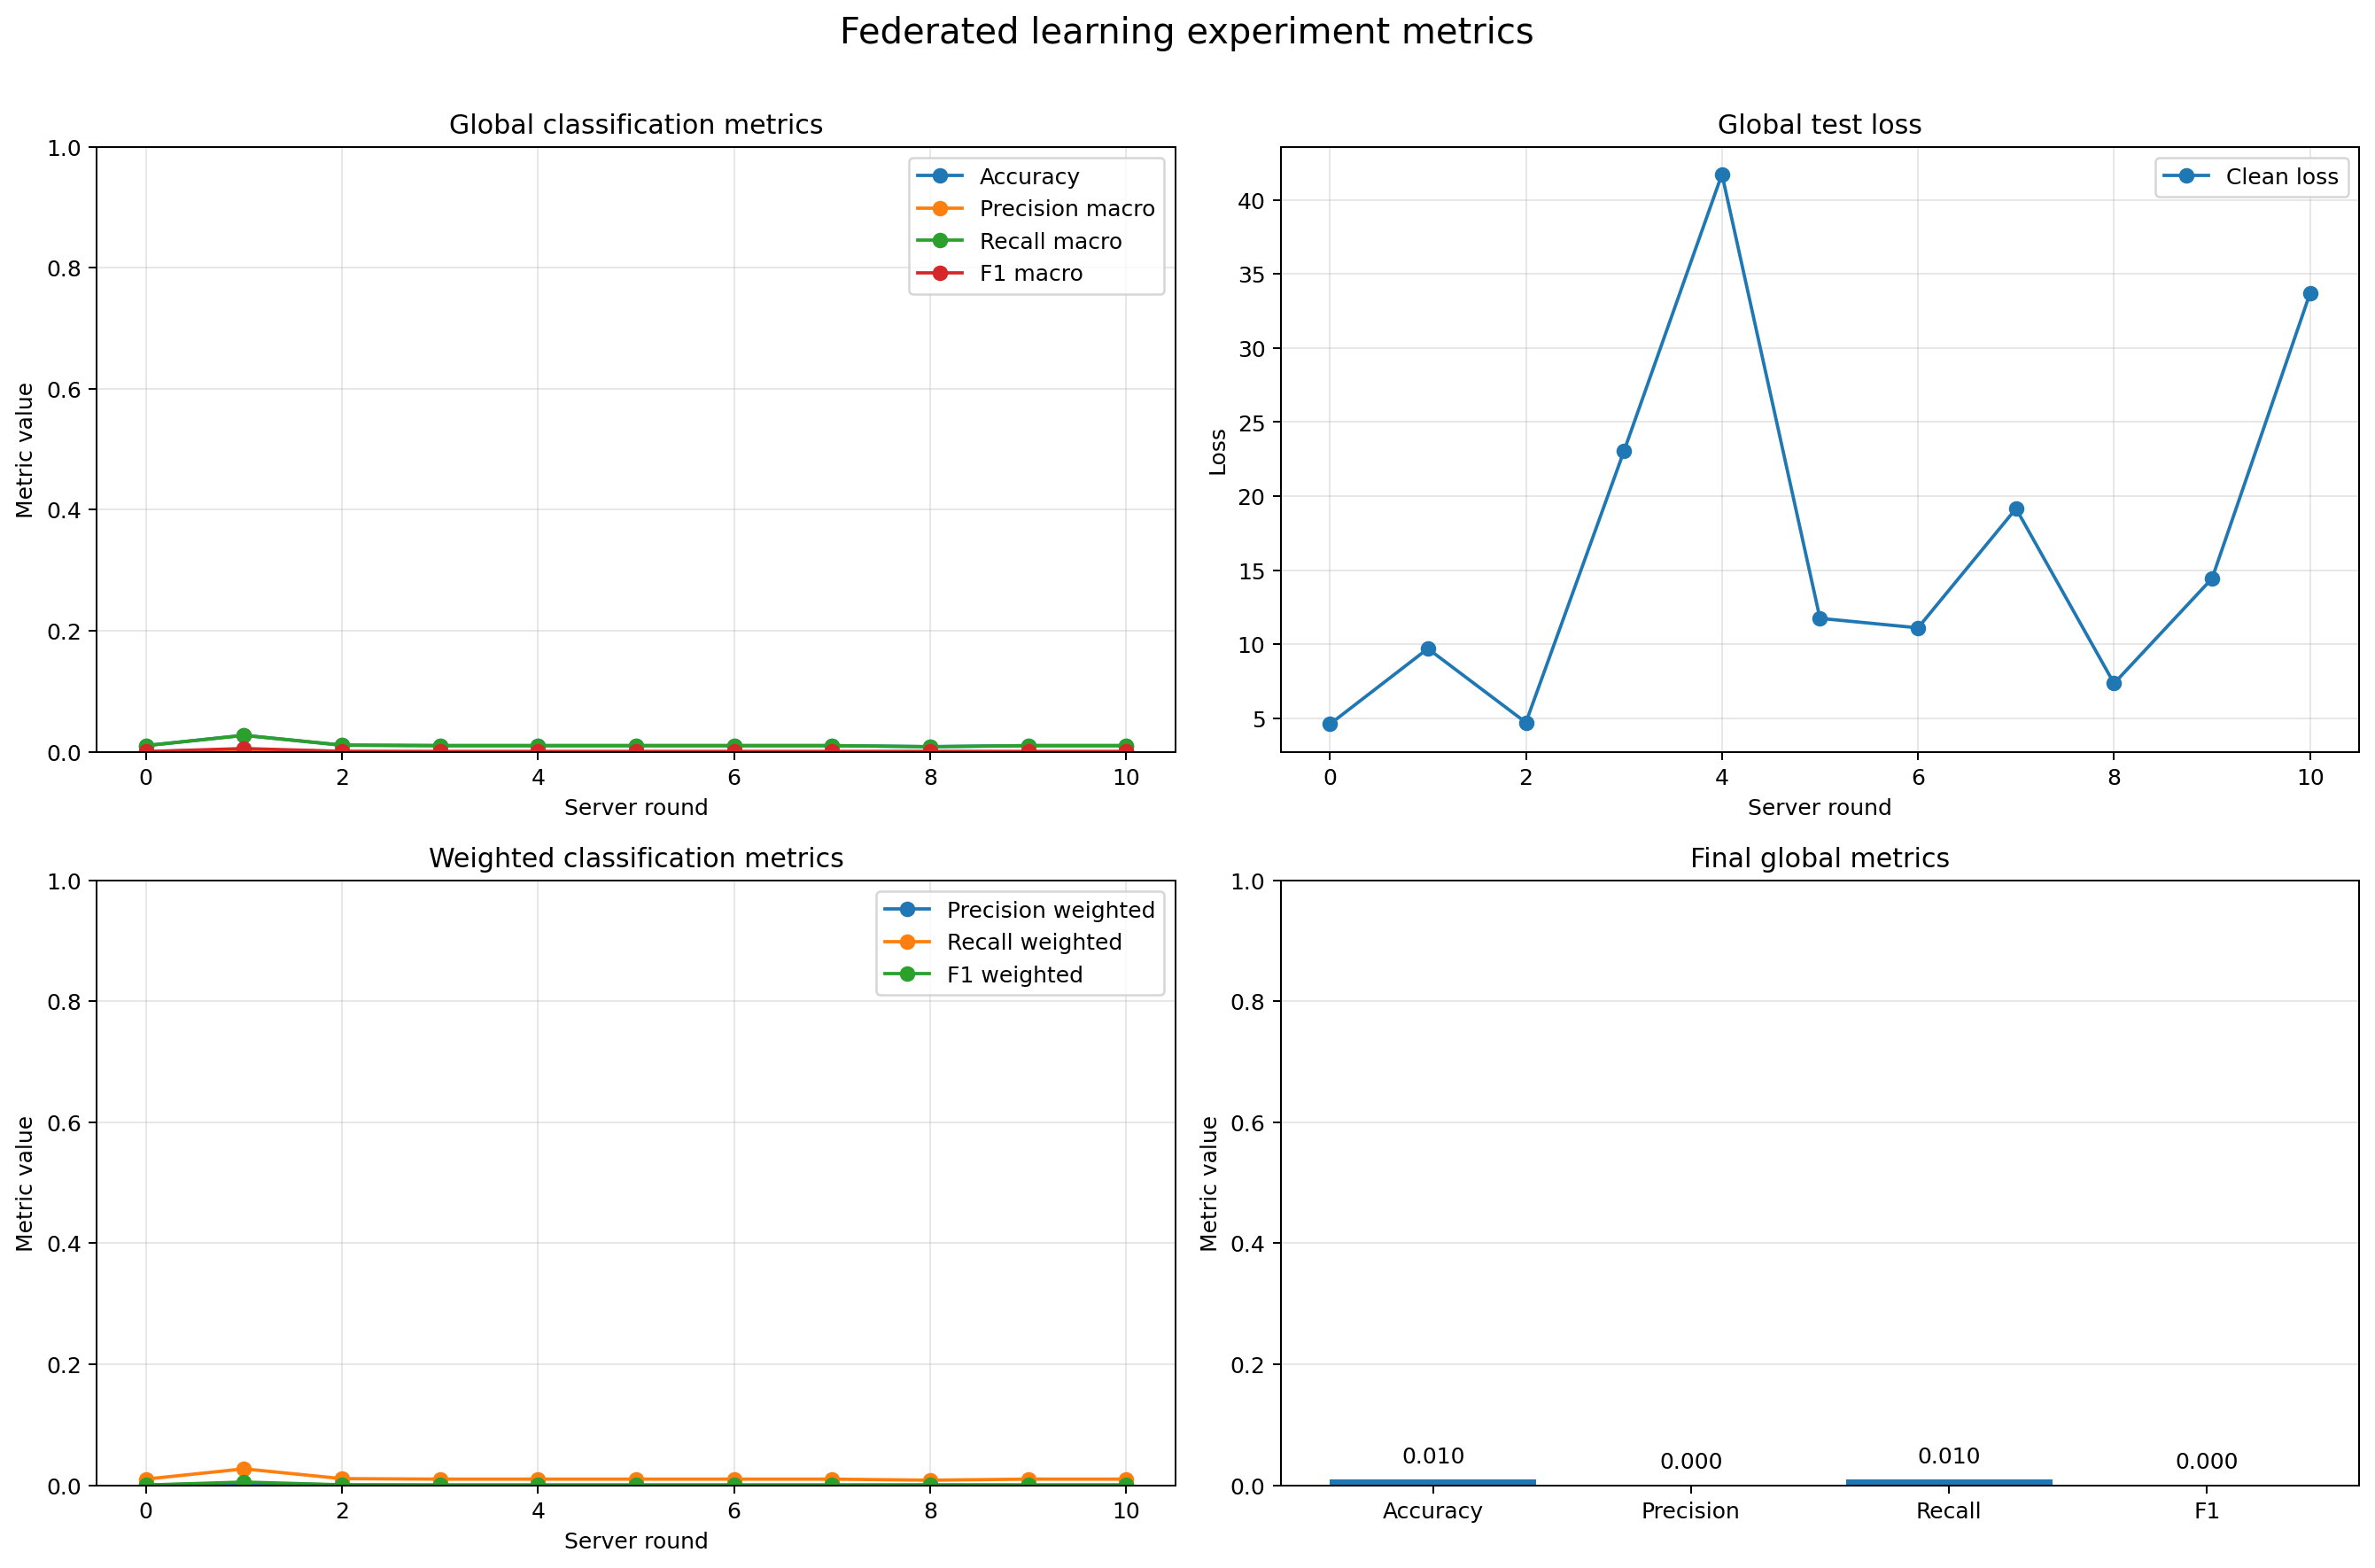

Метрика,Значение
Accuracy,0.0100
Loss,33.7089
Precision macro,0.0001
Recall macro,0.0100
F1 macro,0.0002
Precision weighted,0.0001
Recall weighted,0.0100
F1 weighted,0.0002


### `random_update`

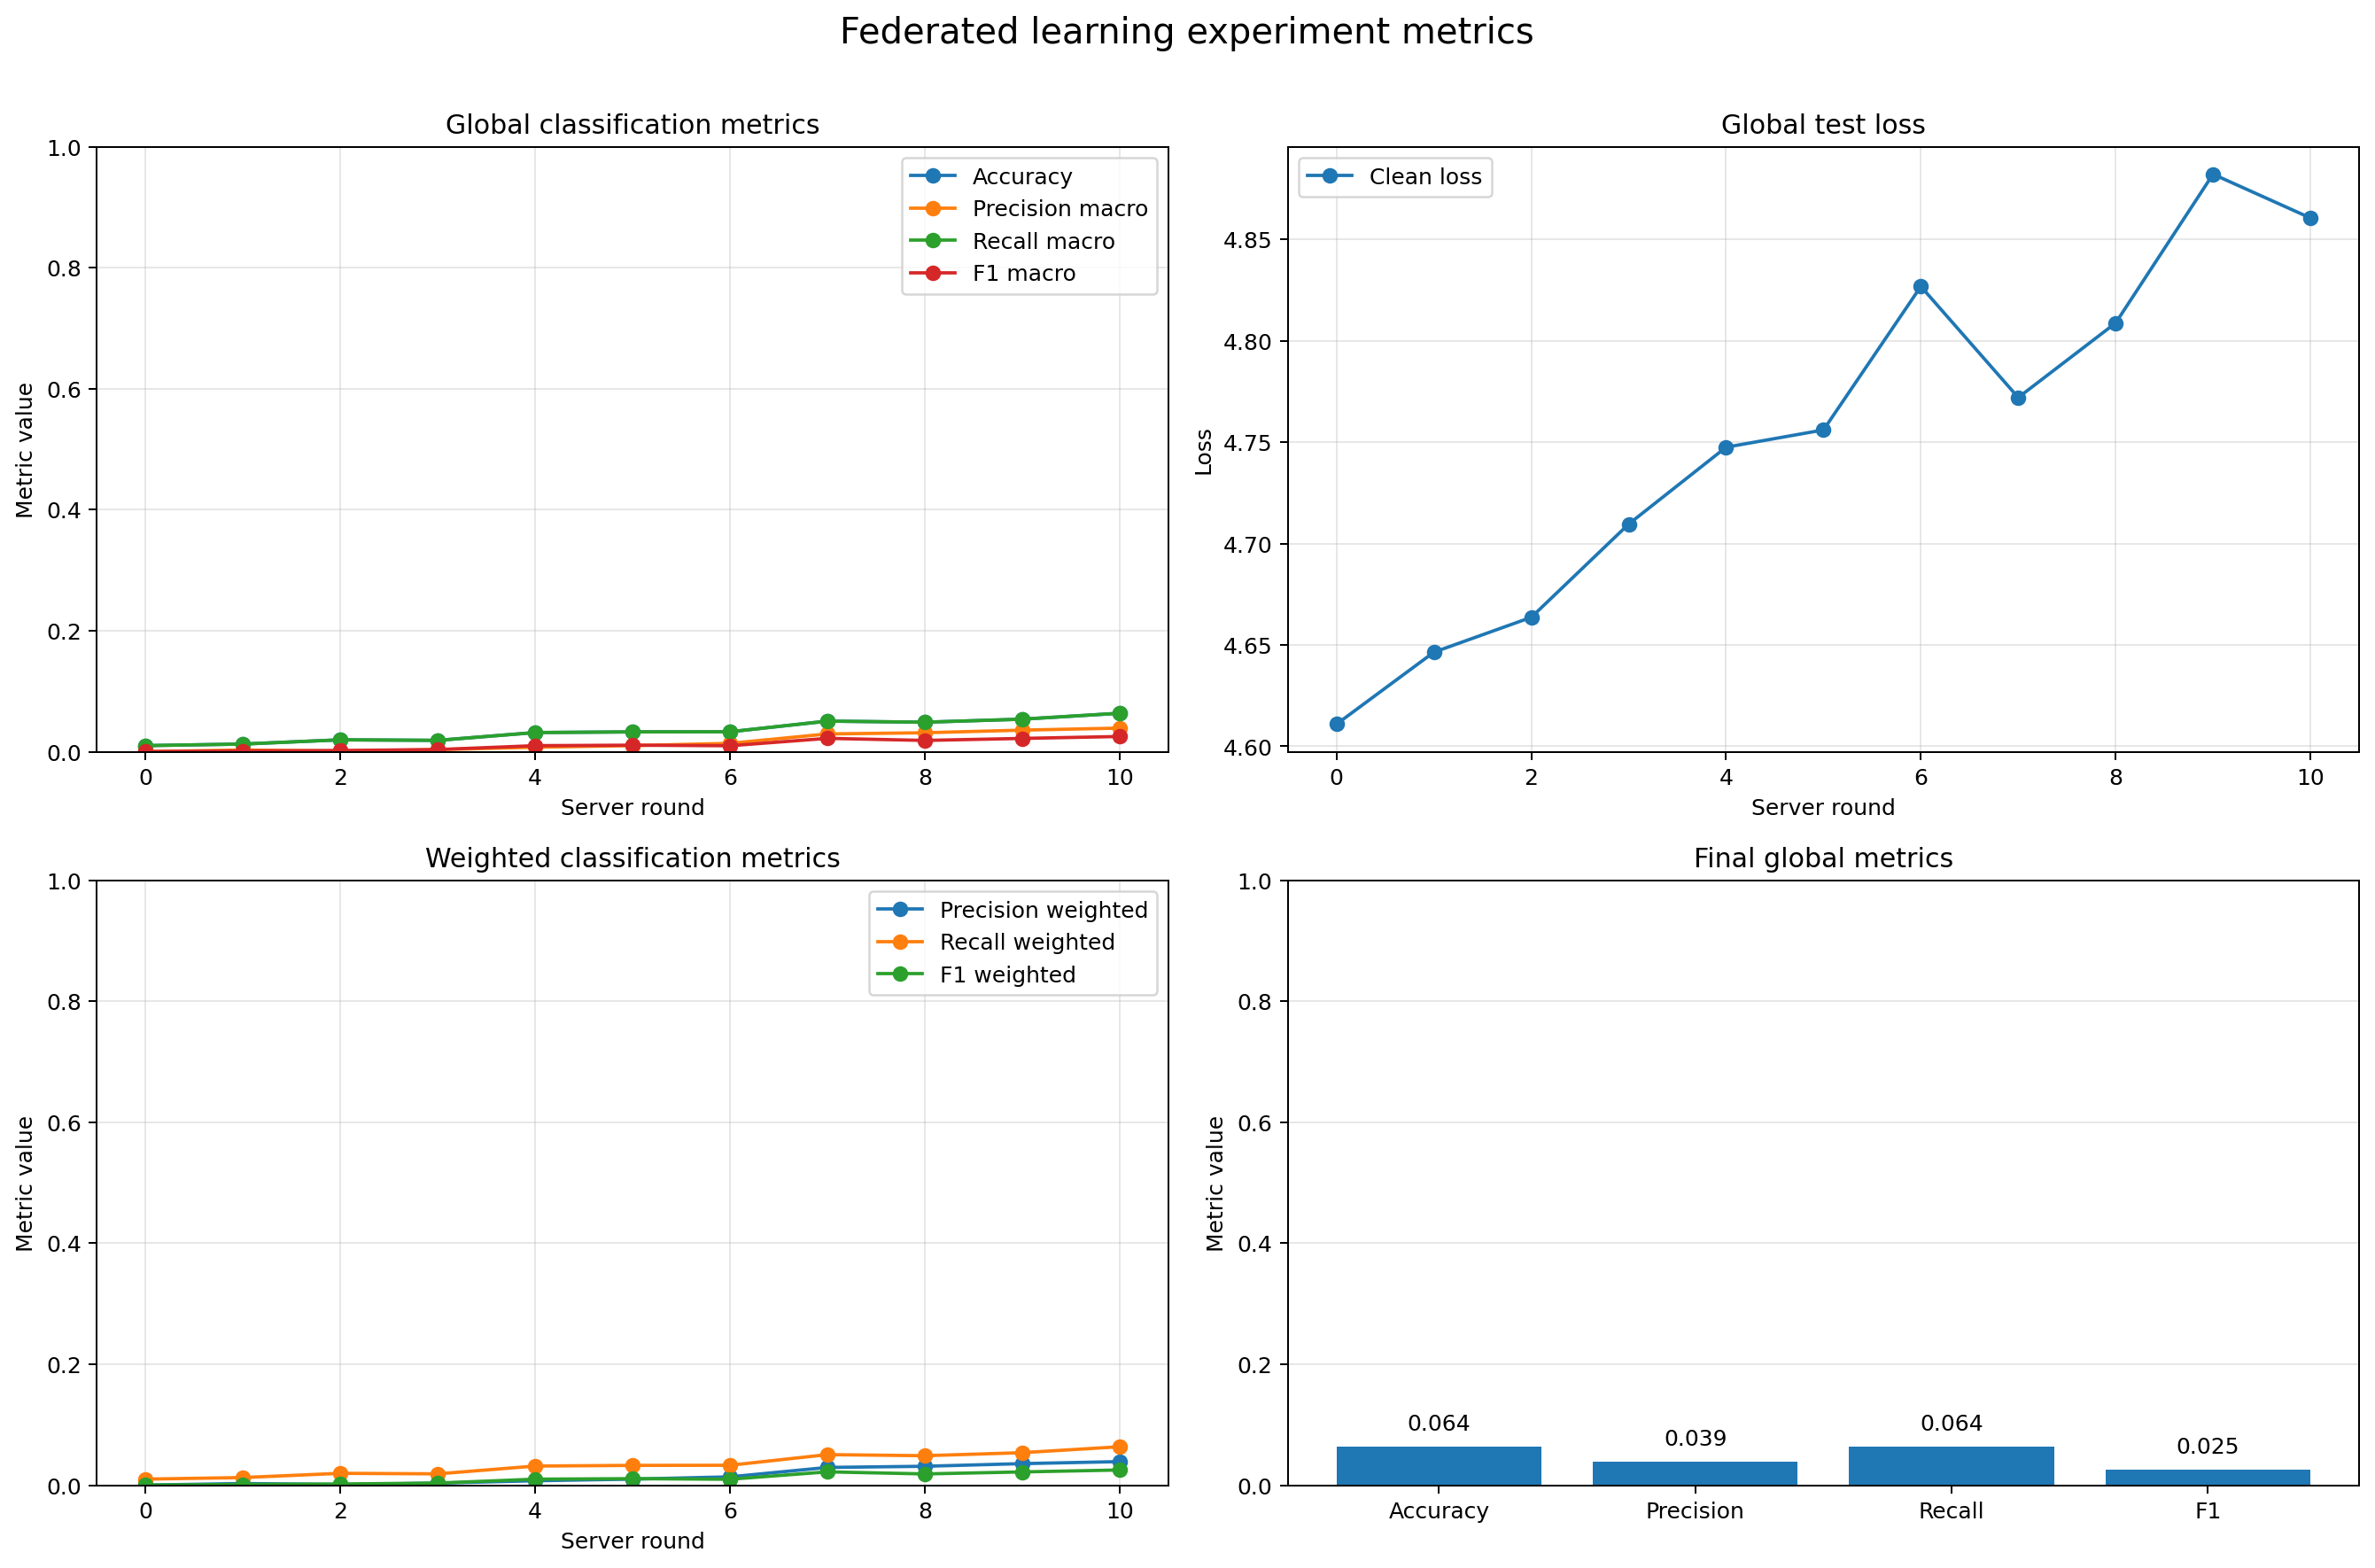

Метрика,Значение
Accuracy,0.0635
Loss,4.8605
Precision macro,0.0389
Recall macro,0.0635
F1 macro,0.0251
Precision weighted,0.0389
Recall weighted,0.0635
F1 weighted,0.0251


In [21]:
for directory in CURRENT_OUTPUT_DIRS:
    config = (
        load_yaml(directory / "config.yaml")
        if (directory / "config.yaml").exists()
        else {}
    )

    attack_name = str(config.get("attack", directory.name))
    display(Markdown(f"### `{attack_name}`"))

    metrics_image = directory / "metrics.png"
    if metrics_image.exists():
        display(Image(filename=str(metrics_image)))

    if SHOW_CONFUSION_MATRICES:
        confusion_image = directory / "confusion_matrix.png"
        if confusion_image.exists():
            display(Image(filename=str(confusion_image)))

    report_path = directory / "classification_report.json"

    if report_path.exists():
        report = json.loads(report_path.read_text(encoding="utf-8"))

        aggregate_rows = [
            ("Accuracy", report.get("accuracy")),
            ("Loss", report.get("loss")),
            (
                "Precision macro",
                report.get("macro_avg", {}).get("precision"),
            ),
            (
                "Recall macro",
                report.get("macro_avg", {}).get("recall"),
            ),
            ("F1 macro", report.get("macro_avg", {}).get("f1")),
            (
                "Precision weighted",
                report.get("weighted_avg", {}).get("precision"),
            ),
            (
                "Recall weighted",
                report.get("weighted_avg", {}).get("recall"),
            ),
            (
                "F1 weighted",
                report.get("weighted_avg", {}).get("f1"),
            ),
        ]

        display(
            pd.DataFrame(
                aggregate_rows,
                columns=["Метрика", "Значение"],
            )
            .style
            .format({"Значение": "{:.4f}"})
            .hide(axis="index")
        )


## 12. Файлы текущего запуска

Показываются только каталоги, созданные текущим запуском ноутбука.


In [22]:
file_rows = []

for directory in CURRENT_OUTPUT_DIRS:
    for path in sorted(directory.rglob("*")):
        if path.is_file():
            file_rows.append(
                {
                    "Experiment": directory.name.split("__")[-1],
                    "File": str(path.relative_to(PROJECT_ROOT)),
                    "Size KB": round(path.stat().st_size / 1024, 1),
                }
            )

display(
    pd.DataFrame(file_rows)
    .style
    .format({"Size KB": "{:.1f}"})
    .hide(axis="index")
)


Experiment,File,Size KB
clean,outputs/2026-09-25__16-49-07__clean/classification_report.json,13.2
clean,outputs/2026-09-25__16-49-07__clean/config.yaml,0.7
clean,outputs/2026-09-25__16-49-07__clean/confusion_matrix.csv,21.2
clean,outputs/2026-09-25__16-49-07__clean/confusion_matrix.png,1458.6
clean,outputs/2026-09-25__16-49-07__clean/final_model.pt,2706.8
clean,outputs/2026-09-25__16-49-07__clean/metrics.csv,1.6
clean,outputs/2026-09-25__16-49-07__clean/metrics.png,228.3
clean,outputs/2026-09-25__16-49-07__clean/summary.json,0.6
sign_flip,outputs/2026-09-25__16-59-19__sign_flip/classification_report.json,10.7
sign_flip,outputs/2026-09-25__16-59-19__sign_flip/config.yaml,0.7


## 13. Упаковка результатов

В архив попадают:

- результаты **текущего** запуска;
- `experiments.yaml`;
- `pyproject.toml`;
- `uv.lock`, если он есть;
- README и описание атак;
- полный лог Kaggle-запуска.


In [23]:
bundle_name = (
    "fl-attacks-lab-results-"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)
bundle_root = WORKING_ROOT / bundle_name
archive_base = WORKING_ROOT / bundle_name

shutil.rmtree(bundle_root, ignore_errors=True)
bundle_root.mkdir(parents=True)

outputs_bundle = bundle_root / "outputs"
outputs_bundle.mkdir()

for directory in CURRENT_OUTPUT_DIRS:
    shutil.copytree(
        directory,
        outputs_bundle / directory.name,
    )

for filename in (
    "pyproject.toml",
    "uv.lock",
    "README.md",
    "attacks.md",
):
    source = PROJECT_ROOT / filename
    if source.exists():
        shutil.copy2(source, bundle_root / filename)

(bundle_root / "configs").mkdir(exist_ok=True)
shutil.copy2(
    PROJECT_ROOT / "configs" / "experiments.yaml",
    bundle_root / "configs" / "experiments.yaml",
)

if LOG_PATH.exists():
    (bundle_root / "logs").mkdir(exist_ok=True)
    shutil.copy2(
        LOG_PATH,
        bundle_root / "logs" / LOG_PATH.name,
    )

archive_path = shutil.make_archive(
    str(archive_base),
    "zip",
    root_dir=bundle_root,
)

section("Архив результатов готов", archive_path)
print(
    "Размер, MB:",
    round(Path(archive_path).stat().st_size / (1024 * 1024), 2),
)
print("Скачайте ZIP из панели Files в Kaggle.")


Размер, MB: 18.2
Скачайте ZIP из панели Files в Kaggle.
